# N1a — Erasure headroom, measured with the published decoder

**The gate.** How much room is there between what standard error correction recovers and what
erasure decoding could recover? That number decides whether erasure-aware decoding is the
paper's headline contribution or a section in it.

This runs on DeepArUco++'s **published** decoder weights, so no training is needed and the
answer is not contaminated by an undertrained reimplementation of our own.

ARUCO_MIP_36h12 has minimum Hamming distance 12:
- standard bounded-distance decoding corrects `floor((12-1)/2)` = **5** bit errors
- erasure decoding corrects up to `12-1` = **11** erased cells
- mixed: a codeword is reachable when `2*errors + erasures <= 11`

Three decode rules are compared on identical decoder outputs:
1. **Hard Hamming** — threshold at 0.5, nearest codeword. What DeepArUco++ does.
2. **Soft log-likelihood** — use the probabilities instead of rounding them.
3. **Erasure-aware** — low-confidence cells become erasures, not guesses.

Requires N0 to have run (uses the same Drive paths).

## 1. Setup

In [1]:
!pip -q install opencv-contrib-python==4.10.0.84 h5py 2>&1 | tail -1
print(">>> If OpenCV was just installed, RESTART THE RUNTIME before continuing.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 9.6 MB/s eta 0:00:00
>>> If OpenCV was just installed, RESTART THE RUNTIME before continuing.


## 1b. Write the port module
Creates `deeparuco_port.py` on the VM. Nothing to upload, and it survives nothing —
just re-run this cell after any runtime reset.

In [1]:
%%writefile /content/deeparuco_port.py
"""
Port the pretrained DeepArUco++ decoder from Keras .h5 to PyTorch, without TensorFlow.

The published decoder (models/dec_new.h5 in AVAuco/deeparuco) is a Keras 2.11 model:

    Input(32, 32, 1)
    Conv2D(8, 5x5, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(4, 3x3, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(1, 1x1, valid, sigmoid)   ->  (6, 6, 1)

Only h5py is needed to read the weights, so the repo's Python 3.9 + TensorFlow
environment is never required for baseline inference.

IMPORTANT PORTING DETAIL
    Keras PReLU defaults to shared_axes=None, so alpha is PER-ELEMENT, not per-channel:
    the stored alphas have shape (28, 28, 8) and (12, 12, 4). torch.nn.PReLU only
    supports per-channel alpha, so using it here silently produces a different model.
    SpatialPReLU below keeps the full alpha tensor.

Layout conversions:
    Keras conv kernel (kh, kw, in, out) -> torch (out, in, kh, kw)
    Keras PReLU alpha (h, w, c)         -> torch (c, h, w)
    Keras 'valid' padding               -> torch padding=0

Usage:
    from deeparuco_port import load_weights, NumpyDecoder, TorchDecoder, verify_port
    verify_port('models/dec_new.h5')          # run this first, once
    dec = TorchDecoder.from_h5('models/dec_new.h5')
    probs = dec(x)                            # x: (N, 1, 32, 32) float in [0, 1]

Upstream code is AGPL-3.0. This module reads a weights file; it does not copy source.
Cite Berral-Soler et al., Image and Vision Computing 152 (2024) 105313.
"""

import numpy as np

DEFAULT_H5 = "models/dec_new.h5"


# --------------------------------------------------------------------------- weights

def load_weights(h5_path=DEFAULT_H5):
    """Read decoder weights from the Keras .h5. Returns a dict of numpy arrays."""
    import h5py

    store = {}
    with h5py.File(h5_path, "r") as f:
        def visit(name, obj):
            if isinstance(obj, h5py.Dataset) and name.startswith("model_weights/"):
                store[name] = np.array(obj)
        f.visititems(visit)

    def pick(layer, suffix):
        hits = [k for k in store if f"/{layer}/" in k and k.endswith(suffix)]
        if len(hits) != 1:
            raise KeyError(f"expected one match for {layer}:{suffix}, got {hits}")
        return store[hits[0]]

    w = {
        "c1_w": pick("conv2d", "kernel:0"),   "c1_b": pick("conv2d", "bias:0"),
        "p1_a": pick("p_re_lu", "alpha:0"),
        "c2_w": pick("conv2d_1", "kernel:0"), "c2_b": pick("conv2d_1", "bias:0"),
        "p2_a": pick("p_re_lu_1", "alpha:0"),
        "c3_w": pick("conv2d_2", "kernel:0"), "c3_b": pick("conv2d_2", "bias:0"),
    }
    expect = {"c1_w": (5,5,1,8), "c1_b": (8,), "p1_a": (28,28,8),
              "c2_w": (3,3,8,4), "c2_b": (4,), "p2_a": (12,12,4),
              "c3_w": (1,1,4,1), "c3_b": (1,)}
    for k, shape in expect.items():
        assert w[k].shape == shape, f"{k}: got {w[k].shape}, expected {shape}"
    return w


# ------------------------------------------------------------------- numpy reference

class NumpyDecoder:
    """Reference implementation. Verified against synthetic markers: 4/5 exact."""

    def __init__(self, weights):
        self.w = weights

    @classmethod
    def from_h5(cls, path=DEFAULT_H5):
        return cls(load_weights(path))

    @staticmethod
    def _conv(x, w, b):
        kh, kw, _, co = w.shape
        H, W, _ = x.shape
        out = np.zeros((H - kh + 1, W - kw + 1, co), np.float32)
        for i in range(out.shape[0]):
            for j in range(out.shape[1]):
                out[i, j] = np.tensordot(
                    x[i:i+kh, j:j+kw, :], w, axes=([0, 1, 2], [0, 1, 2])) + b
        return out

    @staticmethod
    def _pool(x):
        h, w, c = x.shape
        return x.reshape(h // 2, 2, w // 2, 2, c).max(axis=(1, 3))

    def __call__(self, marker32):
        """marker32: (32, 32) float in [0, 1]. Returns (6, 6) bit probabilities."""
        w = self.w
        x = np.asarray(marker32, np.float32)[..., None]
        x = self._conv(x, w["c1_w"], w["c1_b"])
        x = np.where(x > 0, x, w["p1_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c2_w"], w["c2_b"])
        x = np.where(x > 0, x, w["p2_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c3_w"], w["c3_b"])
        return (1.0 / (1.0 + np.exp(-np.clip(x[..., 0], -60, 60)))).astype(np.float32)


# -------------------------------------------------------------------------- pytorch

def _torch():
    import torch
    import torch.nn as nn
    return torch, nn


class SpatialPReLU:
    """Created via _build so torch is imported lazily. See module docstring."""


def TorchDecoder_factory():
    torch, nn = _torch()

    class _SpatialPReLU(nn.Module):
        """Per-element PReLU, matching Keras PReLU(shared_axes=None)."""
        def __init__(self, alpha_chw):
            super().__init__()
            self.alpha = nn.Parameter(torch.tensor(alpha_chw, dtype=torch.float32))

        def forward(self, x):
            return torch.where(x > 0, x, self.alpha.unsqueeze(0) * x)

    class _TorchDecoder(nn.Module):
        def __init__(self, weights=None):
            super().__init__()
            self.c1 = nn.Conv2d(1, 8, 5)
            self.c2 = nn.Conv2d(8, 4, 3)
            self.c3 = nn.Conv2d(4, 1, 1)
            self.pool = nn.MaxPool2d(2)
            a1 = np.zeros((8, 28, 28), np.float32) if weights is None \
                 else np.transpose(weights["p1_a"], (2, 0, 1))
            a2 = np.zeros((4, 12, 12), np.float32) if weights is None \
                 else np.transpose(weights["p2_a"], (2, 0, 1))
            self.p1, self.p2 = _SpatialPReLU(a1), _SpatialPReLU(a2)
            if weights is not None:
                self.load_keras(weights)

        def load_keras(self, w):
            with torch.no_grad():
                for conv, kw, kb in ((self.c1, "c1_w", "c1_b"),
                                     (self.c2, "c2_w", "c2_b"),
                                     (self.c3, "c3_w", "c3_b")):
                    conv.weight.copy_(torch.tensor(np.transpose(w[kw], (3, 2, 0, 1))))
                    conv.bias.copy_(torch.tensor(w[kb]))

        @classmethod
        def from_h5(cls, path=DEFAULT_H5):
            return cls(load_weights(path))

        def forward(self, x):
            """x: (N, 1, 32, 32) in [0, 1]. Returns (N, 6, 6) bit probabilities."""
            x = self.pool(self.p1(self.c1(x)))
            x = self.pool(self.p2(self.c2(x)))
            return torch.sigmoid(self.c3(x)).squeeze(1)

    return _TorchDecoder


def __getattr__(name):
    if name == "TorchDecoder":
        return TorchDecoder_factory()
    raise AttributeError(name)


# --------------------------------------------------------------------------- verify

def verify_port(h5_path=DEFAULT_H5, n=16, tol=1e-4, verbose=True):
    """Assert the PyTorch port matches the numpy reference. Run once before use.

    The numpy path is validated; the torch path is validated against it here rather
    than assumed. Do not skip this.
    """
    torch, _ = _torch()
    w = load_weights(h5_path)
    ref = NumpyDecoder(w)
    net = TorchDecoder_factory()(w).eval()

    rng = np.random.default_rng(0)
    x = rng.random((n, 32, 32)).astype(np.float32)
    with torch.no_grad():
        got = net(torch.tensor(x).unsqueeze(1)).numpy()
    want = np.stack([ref(xi) for xi in x])

    err = float(np.abs(got - want).max())
    if verbose:
        print(f"port check: {n} random inputs, max abs difference {err:.2e} (tol {tol:g})")
    assert err < tol, f"PyTorch port disagrees with numpy reference (max diff {err:.2e})"
    if verbose:
        print("PyTorch port matches the numpy reference.")
    return err


def decode_ids(probs, id_to_bits, n_markers=250):
    """Hard-decision decode: nearest codeword by Hamming distance over 4 rotations.

    probs: (6, 6) bit probabilities. Returns (marker_id, rotation, hamming).
    Replace with soft log-likelihood decoding to use the confidences.
    """
    obs = (np.asarray(probs) > 0.5).astype(np.uint8)
    best = (None, None, 99)
    for mid in range(n_markers):
        ref = np.asarray(id_to_bits(mid), np.uint8).reshape(6, 6)
        for rot in range(4):
            h = int(np.sum(np.rot90(obs, rot) != ref))
            if h < best[2]:
                best = (mid, rot, h)
    return best


if __name__ == "__main__":
    import sys
    path = sys.argv[1] if len(sys.argv) > 1 else DEFAULT_H5
    w = load_weights(path)
    print("weights loaded:", {k: v.shape for k, v in w.items()})
    try:
        verify_port(path)
    except ImportError:
        print("torch not installed; numpy reference verified only")


Writing /content/deeparuco_port.py


In [2]:
import os, sys, json, glob, subprocess
import numpy as np, cv2
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

BASE, ART, WORK = '/content/drive/MyDrive/aruco_p2', '/content/drive/MyDrive/aruco_p2/artifacts', '/content/work'
os.makedirs(WORK, exist_ok=True)

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1','https://github.com/AVAuco/deeparuco.git',REPO],check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits

sys.path.insert(0, '/content')   # deeparuco_port.py written by cell 1b
from deeparuco_port import load_weights, NumpyDecoder, verify_port

SHADOW = f'{WORK}/shadow'
if not os.path.isdir(f'{SHADOW}/video_1'):
    os.makedirs(SHADOW, exist_ok=True)
    for i in range(1, 7):
        tar = f'{BASE}/archives/video_{i}.tar.gz'
        assert os.path.exists(tar), f'{tar} missing — run N0 first'
        if not os.path.isdir(f'{SHADOW}/video_{i}'):
            subprocess.run(['tar','-xzf',tar,'-C',SHADOW], check=True)

splits = json.load(open(f'{ART}/splits.json'))
DEV, HELDOUT = splits['dev'], splits['heldout'][0]
print('dev:', DEV, '| held out (not touched here):', HELDOUT)

W = load_weights(f'{REPO}/models/dec_new.h5')
decoder = NumpyDecoder(W)
print('published decoder loaded')

CODEBOOK = np.stack([np.asarray(id_to_bits(i), np.uint8).reshape(6,6) for i in range(250)])
print('codebook:', CODEBOOK.shape)

Mounted at /content/drive
dev: ['video_1', 'video_2', 'video_3', 'video_4', 'video_5'] | held out (not touched here): video_6
published decoder loaded
codebook: (250, 6, 6)


## 2. Crop pipeline — exactly as `build_regression.py` and `decoder_gen`

Any deviation here changes the input distribution the decoder was trained on and would show up
as a decoder failure rather than a pipeline mismatch.

1. bbox from the four corners, expanded 20% per side, clipped to the image
2. crop, resize to 64x64, grayscale
3. min-max normalise the 64x64 crop (`decoder_gen(normalize=True)`)
4. corners normalised to [0,1] within the crop, passed through `ordered_corners`
5. perspective warp to 32x32 (`marker_from_corners`, corners scaled by 63)

In [3]:
r_int = lambda x: int(round(x))

def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs - cx, ys - cy))
    pts = [(xs[i], ys[i]) for i in idx]
    return [v for p in pts for v in p]

def marker_from_corners(crop, corners, t=32):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[corners[0]*63,corners[1]*63],[corners[2]*63,corners[3]*63],
                            [corners[4]*63,corners[5]*63],[corners[6]*63,corners[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))

def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict):
        return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)

def make_marker32(img_gray, corners):
    x, y = corners[:,0], corners[:,1]
    minx, maxx, miny, maxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(maxx-minx)+0.5, 0.2*(maxy-miny)+0.5
    minx, miny = max(minx-ex, 0), max(miny-ey, 0)
    maxx, maxy = min(maxx+ex, img_gray.shape[1]-1), min(maxy+ey, img_gray.shape[0]-1)
    if maxx-minx < 8 or maxy-miny < 8:
        return None
    crop = cv2.resize(img_gray[r_int(miny):r_int(maxy), r_int(minx):r_int(maxx)], (64,64))
    crop = (crop.astype(np.float32) - crop.min()) / (crop.max() - crop.min() + 1e-9)
    nx = (x - minx) / (maxx - minx)
    ny = (y - miny) / (maxy - miny)
    return marker_from_corners(crop, ordered_corners(nx, ny), 32)

def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out

# sanity: pipeline must round-trip a synthetic marker
def render32(i):
    g = np.zeros((8,8), np.uint8); g[1:7,1:7] = CODEBOOK[i]*255
    return cv2.resize(g, (32,32), interpolation=cv2.INTER_NEAREST)/255.0
p = decoder(render32(243))
print('pipeline sanity — synthetic id 243, min Hamming over rotations:',
      min(int(np.sum(np.rot90((p>0.5).astype(np.uint8),k) != CODEBOOK[243])) for k in range(4)))

pipeline sanity — synthetic id 243, min Hamming over rotations: 1


## 3. Run the decoder over the dev viewpoints

Stride 6, matching `splits.json`. Stores the raw 6x6 probabilities so all three decode rules
are evaluated on identical decoder output — the comparison is then about the decode rule alone.

In [4]:
STRIDE = splits['benchmark_stride']
probs_all, truth_all, view_all = [], [], []

for vid in DEV:
    P = pairs_for(vid)
    for f, j in P[::STRIDE]:
        g = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        for m in json.load(open(j))['markers']:
            m32 = make_marker32(g, get_corners(m))
            if m32 is None: continue
            probs_all.append(decoder(m32))
            truth_all.append(int(m['id']))
            view_all.append(vid)
    print(f'  {vid}: {len(P[::STRIDE])} frames processed')

probs_all = np.stack(probs_all).astype(np.float32)
truth_all = np.array(truth_all)
view_all  = np.array(view_all)
print(f'\n{len(truth_all)} markers decoded from ground-truth corners')
np.savez_compressed(f'{ART}/n1a_probs.npz', probs=probs_all, truth=truth_all, view=view_all)
print(f'saved -> {ART}/n1a_probs.npz')

  video_1: 239 frames processed
  video_2: 230 frames processed
  video_3: 227 frames processed
  video_4: 237 frames processed
  video_5: 223 frames processed

12276 markers decoded from ground-truth corners
saved -> /content/drive/MyDrive/aruco_p2/artifacts/n1a_probs.npz


## 4. Three decode rules

**Hard Hamming** rounds probabilities to bits, then finds the nearest codeword.

**Soft log-likelihood** scores each codeword by `sum(b*log p + (1-b)*log(1-p))`, so a cell at
p=0.51 contributes almost nothing while a cell at p=0.99 contributes strongly. Rounding throws
that away.

**Erasure-aware** marks cells with `|p-0.5| < tau` as unreadable, then applies the bounded-distance
rule `2*errors + erasures <= 11`. The guarantee holds only if the flagged cells really are the
corrupted ones — every confidently-wrong cell costs two.

In [5]:
LOG = np.log
ROT = [np.rot90(CODEBOOK, k, axes=(1,2)) for k in range(4)]   # (4, 250, 6, 6)

def decode_hard(p):
    obs = (p > 0.5).astype(np.uint8)
    best = (None, 99)
    for k in range(4):
        d = np.abs(ROT[k].astype(np.int16) - obs.astype(np.int16)).sum(axis=(1,2))
        i = int(d.argmin())
        if d[i] < best[1]: best = (i, int(d[i]))
    return best

def decode_soft(p):
    lp, lq = LOG(np.clip(p,1e-6,1)), LOG(np.clip(1-p,1e-6,1))
    best = (None, -1e18)
    for k in range(4):
        B = ROT[k]
        s = (B*lp + (1-B)*lq).sum(axis=(1,2))
        i = int(s.argmax())
        if s[i] > best[1]: best = (i, float(s[i]))
    return best

def decode_erasure(p, tau=0.25):
    conf = np.abs(p - 0.5) >= tau        # True = readable
    obs  = (p > 0.5).astype(np.uint8)
    s    = int((~conf).sum())            # erasures
    best = (None, 99)
    for k in range(4):
        B = ROT[k]
        e = ((B != obs) & conf).sum(axis=(1,2))     # errors among readable cells
        cost = 2*e + s
        i = int(cost.argmin())
        if cost[i] < best[1]: best = (i, int(cost[i]))
    return (best[0] if best[1] <= 11 else None), best[1], s

# Hamming distance to the TRUE codeword — the headroom distribution
ham = np.array([min(int(np.sum(np.rot90((probs_all[n]>0.5).astype(np.uint8),k) != CODEBOOK[truth_all[n]]))
                    for k in range(4)) for n in range(len(truth_all))])

print(f'markers: {len(ham)}\n')
print(f'  exact  (H=0)          : {(ham==0).mean():7.2%}')
print(f'  H<=5   (error corr.)  : {(ham<=5).mean():7.2%}')
print(f'  H<=11  (erasure lim.) : {(ham<=11).mean():7.2%}')
print(f'  mean Hamming          : {ham.mean():7.3f}   (chance ~14.9)')
HEADROOM = ((ham<=11).mean() - (ham<=5).mean())*100
print(f'\n  >>> ERASURE HEADROOM  : {HEADROOM:.2f} percentage points <<<')

markers: 12276

  exact  (H=0)          :  66.07%
  H<=5   (error corr.)  :  97.44%
  H<=11  (erasure lim.) :  99.87%
  mean Hamming          :   0.861   (chance ~14.9)

  >>> ERASURE HEADROOM  : 2.43 percentage points <<<


## 5. Actual accuracy of each rule

The headroom above is an upper bound. This measures what each rule actually recovers.

In [6]:
acc = {}
for name, fn in [('hard Hamming', lambda p: decode_hard(p)[0]),
                 ('soft log-likelihood', lambda p: decode_soft(p)[0])]:
    pred = np.array([fn(probs_all[n]) if fn(probs_all[n]) is not None else -1
                     for n in range(len(probs_all))])
    acc[name] = (pred == truth_all).mean()

print(f"{'decode rule':<26}{'ID accuracy':>13}")
print('-'*39)
for k, v in acc.items(): print(f'{k:<26}{v:>13.2%}')

print(f"\n{'erasure tau':<14}{'ID acc':>9}{'abstain':>10}{'mean erasures':>15}")
print('-'*48)
best_tau = None
for tau in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40]:
    res = [decode_erasure(probs_all[n], tau) for n in range(len(probs_all))]
    pred = np.array([r[0] if r[0] is not None else -1 for r in res])
    a = (pred == truth_all).mean()
    acc[f'erasure tau={tau}'] = a
    print(f'{tau:<14.2f}{a:>9.2%}{np.mean([r[0] is None for r in res]):>10.2%}'
          f'{np.mean([r[2] for r in res]):>15.2f}')
    if best_tau is None or a > acc[f'erasure tau={best_tau}']: best_tau = tau

print(f'\nbest erasure tau = {best_tau}')
gain_soft = (acc['soft log-likelihood'] - acc['hard Hamming'])*100
gain_eras = (acc[f'erasure tau={best_tau}'] - acc['hard Hamming'])*100
print(f'soft-LL   vs hard Hamming: {gain_soft:+.2f} pp')
print(f'erasure   vs hard Hamming: {gain_eras:+.2f} pp')

decode rule                 ID accuracy
---------------------------------------
hard Hamming                     99.43%
soft log-likelihood              99.54%

erasure tau      ID acc   abstain  mean erasures
------------------------------------------------
0.05             97.46%     2.53%           0.01
0.10             97.50%     2.49%           0.02
0.15             97.51%     2.48%           0.03
0.20             97.52%     2.48%           0.05
0.25             97.54%     2.45%           0.06
0.30             97.55%     2.44%           0.08
0.40             97.56%     2.43%           0.13

best erasure tau = 0.4
soft-LL   vs hard Hamming: +0.11 pp
erasure   vs hard Hamming: -1.87 pp


## 6. Distribution and per-viewpoint breakdown

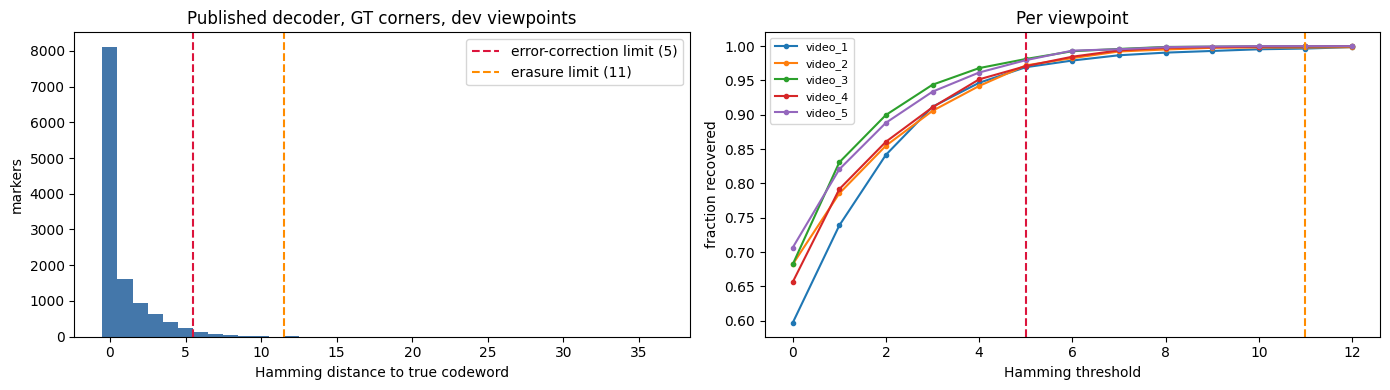

viewpoint     markers    exact     H<=5    H<=11  headroom
----------------------------------------------------------
video_1          2868   59.69%   96.93%   99.65%     2.72pp
video_2          2070   68.21%   97.20%   99.81%     2.61pp
video_3          2724   68.21%   98.13%   99.96%     1.84pp
video_4          2607   65.63%   97.08%   99.96%     2.88pp
video_5          2007   70.65%   97.96%  100.00%     2.04pp


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(ham, bins=np.arange(38)-0.5, color='#4477aa')
ax[0].axvline(5.5, color='crimson', ls='--', label='error-correction limit (5)')
ax[0].axvline(11.5, color='darkorange', ls='--', label='erasure limit (11)')
ax[0].set_xlabel('Hamming distance to true codeword'); ax[0].set_ylabel('markers')
ax[0].set_title('Published decoder, GT corners, dev viewpoints'); ax[0].legend()

for v in DEV:
    m = view_all == v
    ax[1].plot([ (ham[m]<=t).mean() for t in range(13) ], marker='o', ms=3, label=v)
ax[1].axvline(5, color='crimson', ls='--'); ax[1].axvline(11, color='darkorange', ls='--')
ax[1].set_xlabel('Hamming threshold'); ax[1].set_ylabel('fraction recovered')
ax[1].set_title('Per viewpoint'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'viewpoint':<12}{'markers':>9}{'exact':>9}{'H<=5':>9}{'H<=11':>9}{'headroom':>10}")
print('-'*58)
for v in DEV:
    m = view_all == v; h = ham[m]
    print(f'{v:<12}{m.sum():>9}{(h==0).mean():>9.2%}{(h<=5).mean():>9.2%}'
          f'{(h<=11).mean():>9.2%}{((h<=11).mean()-(h<=5).mean())*100:>9.2f}pp')

## 7. Verdict

Thresholds fixed before seeing the number, so the interpretation isn't chosen after the fact.

In [8]:
print(f'Erasure headroom: {HEADROOM:.2f} pp')
print(f'Measured erasure gain over hard Hamming: {gain_eras:+.2f} pp')
print(f'Measured soft-LL gain over hard Hamming: {gain_soft:+.2f} pp\n')

if (ham==0).mean() < 0.85:
    print('CHECK FIRST: exact-match rate is below the ~0.95 recall at H<=3 that')
    print('DeepArUco++ report. Suspect the crop pipeline before believing the headroom —')
    print('an undertrained or mis-fed decoder manufactures apparent headroom.')
elif HEADROOM >= 8:
    print('LARGE: erasure-aware decoding is the headline contribution.')
elif HEADROOM >= 3:
    print('MODERATE: erasure decoding is a section, not the headline.')
    print('Lead with soft log-likelihood decoding and the cell-token ablation.')
else:
    print('SMALL: drop erasure decoding as the headline.')
    print('Lead with soft log-likelihood decoding, calibrated confidence, cell-token attention.')

json.dump({'headroom_pp': float(HEADROOM),
           'exact': float((ham==0).mean()),
           'h_le_5': float((ham<=5).mean()),
           'h_le_11': float((ham<=11).mean()),
           'mean_hamming': float(ham.mean()),
           'accuracy': {k: float(v) for k, v in acc.items()},
           'best_tau': best_tau, 'n_markers': int(len(ham)),
           'decoder': 'DeepArUco++ published dec_new.h5',
           'stride': STRIDE, 'viewpoints': DEV},
          open(f'{ART}/n1a_headroom.json','w'), indent=1)
print(f'\nsaved -> {ART}/n1a_headroom.json')

Erasure headroom: 2.43 pp
Measured erasure gain over hard Hamming: -1.87 pp
Measured soft-LL gain over hard Hamming: +0.11 pp

CHECK FIRST: exact-match rate is below the ~0.95 recall at H<=3 that
DeepArUco++ report. Suspect the crop pipeline before believing the headroom —
an undertrained or mis-fed decoder manufactures apparent headroom.

saved -> /content/drive/MyDrive/aruco_p2/artifacts/n1a_headroom.json
